# Querying regions and building GRIL features

A finite encoding gives us spaces **and maps**. We can therefore ask which vectors persist compatibly through a branching region, rather than asking only for the rank of one arrow. This guide explores three related questions: the rank on selected finite labels, a boundary barcode that explains that rank on a grid, and the width of a continuous worm that still carries a requested number of classes.

You will need TamerOp and CairoMakie, matrix multiplication, and the idea of a [finite module](../spaces_and_maps.md). We start directly from algebraic data; no point cloud or filtration is needed. `A = OP.Advanced` exposes the finite-poset constructors and optional witnesses. The [implementation account](../implementation/generalized_rank.md) develops the limit-to-colimit computation; the [reference](../src/reference/visual_sessions.md#query-generalized-rank-regions) gives the interactive contract.

In [1]:
import TamerOp as OP
using CairoMakie
const A = OP.Advanced
const QQ = Rational{BigInt}
field = OP.CoreModules.QQField();

TamerOp.CoreModules.CoeffFields.QQField()

## Ask a branching-region question

Vertices 1 and 2 each carry a line; their common target 3 carries a plane. In `parallel`, both arrows land on the first coordinate axis. In `transverse`, the second arrow lands on the second axis. Every arrow has rank one in both modules. Do those lines have a nonzero vector in common?

A compatible choice must agree after travelling along either arrow. Generalized rank counts its surviving image after the identifications made by all the maps. On this fork, it is the dimension of the intersection of the two images.

In [2]:
fork = A.FinitePoset(Bool[1 0 1; 0 1 1; 0 0 1])
parallel = A.PModule{QQ}(fork, [1, 1, 2],
    Dict((1, 3) => reshape(QQ[1, 0], 2, 1),
         (2, 3) => reshape(QQ[1, 0], 2, 1)); field)
transverse = A.PModule{QQ}(fork, [1, 1, 2],
    Dict((1, 3) => reshape(QQ[1, 0], 2, 1),
         (2, 3) => reshape(QQ[0, 1], 2, 1)); field)
@assert Dict(OP.rank_invariant(parallel)) == Dict(OP.rank_invariant(transverse))
ranks = (OP.generalized_rank(parallel; vertices=1:3),
         OP.generalized_rank(transverse; vertices=1:3))
@assert ranks == (1, 0)
ranks

(1, 0)

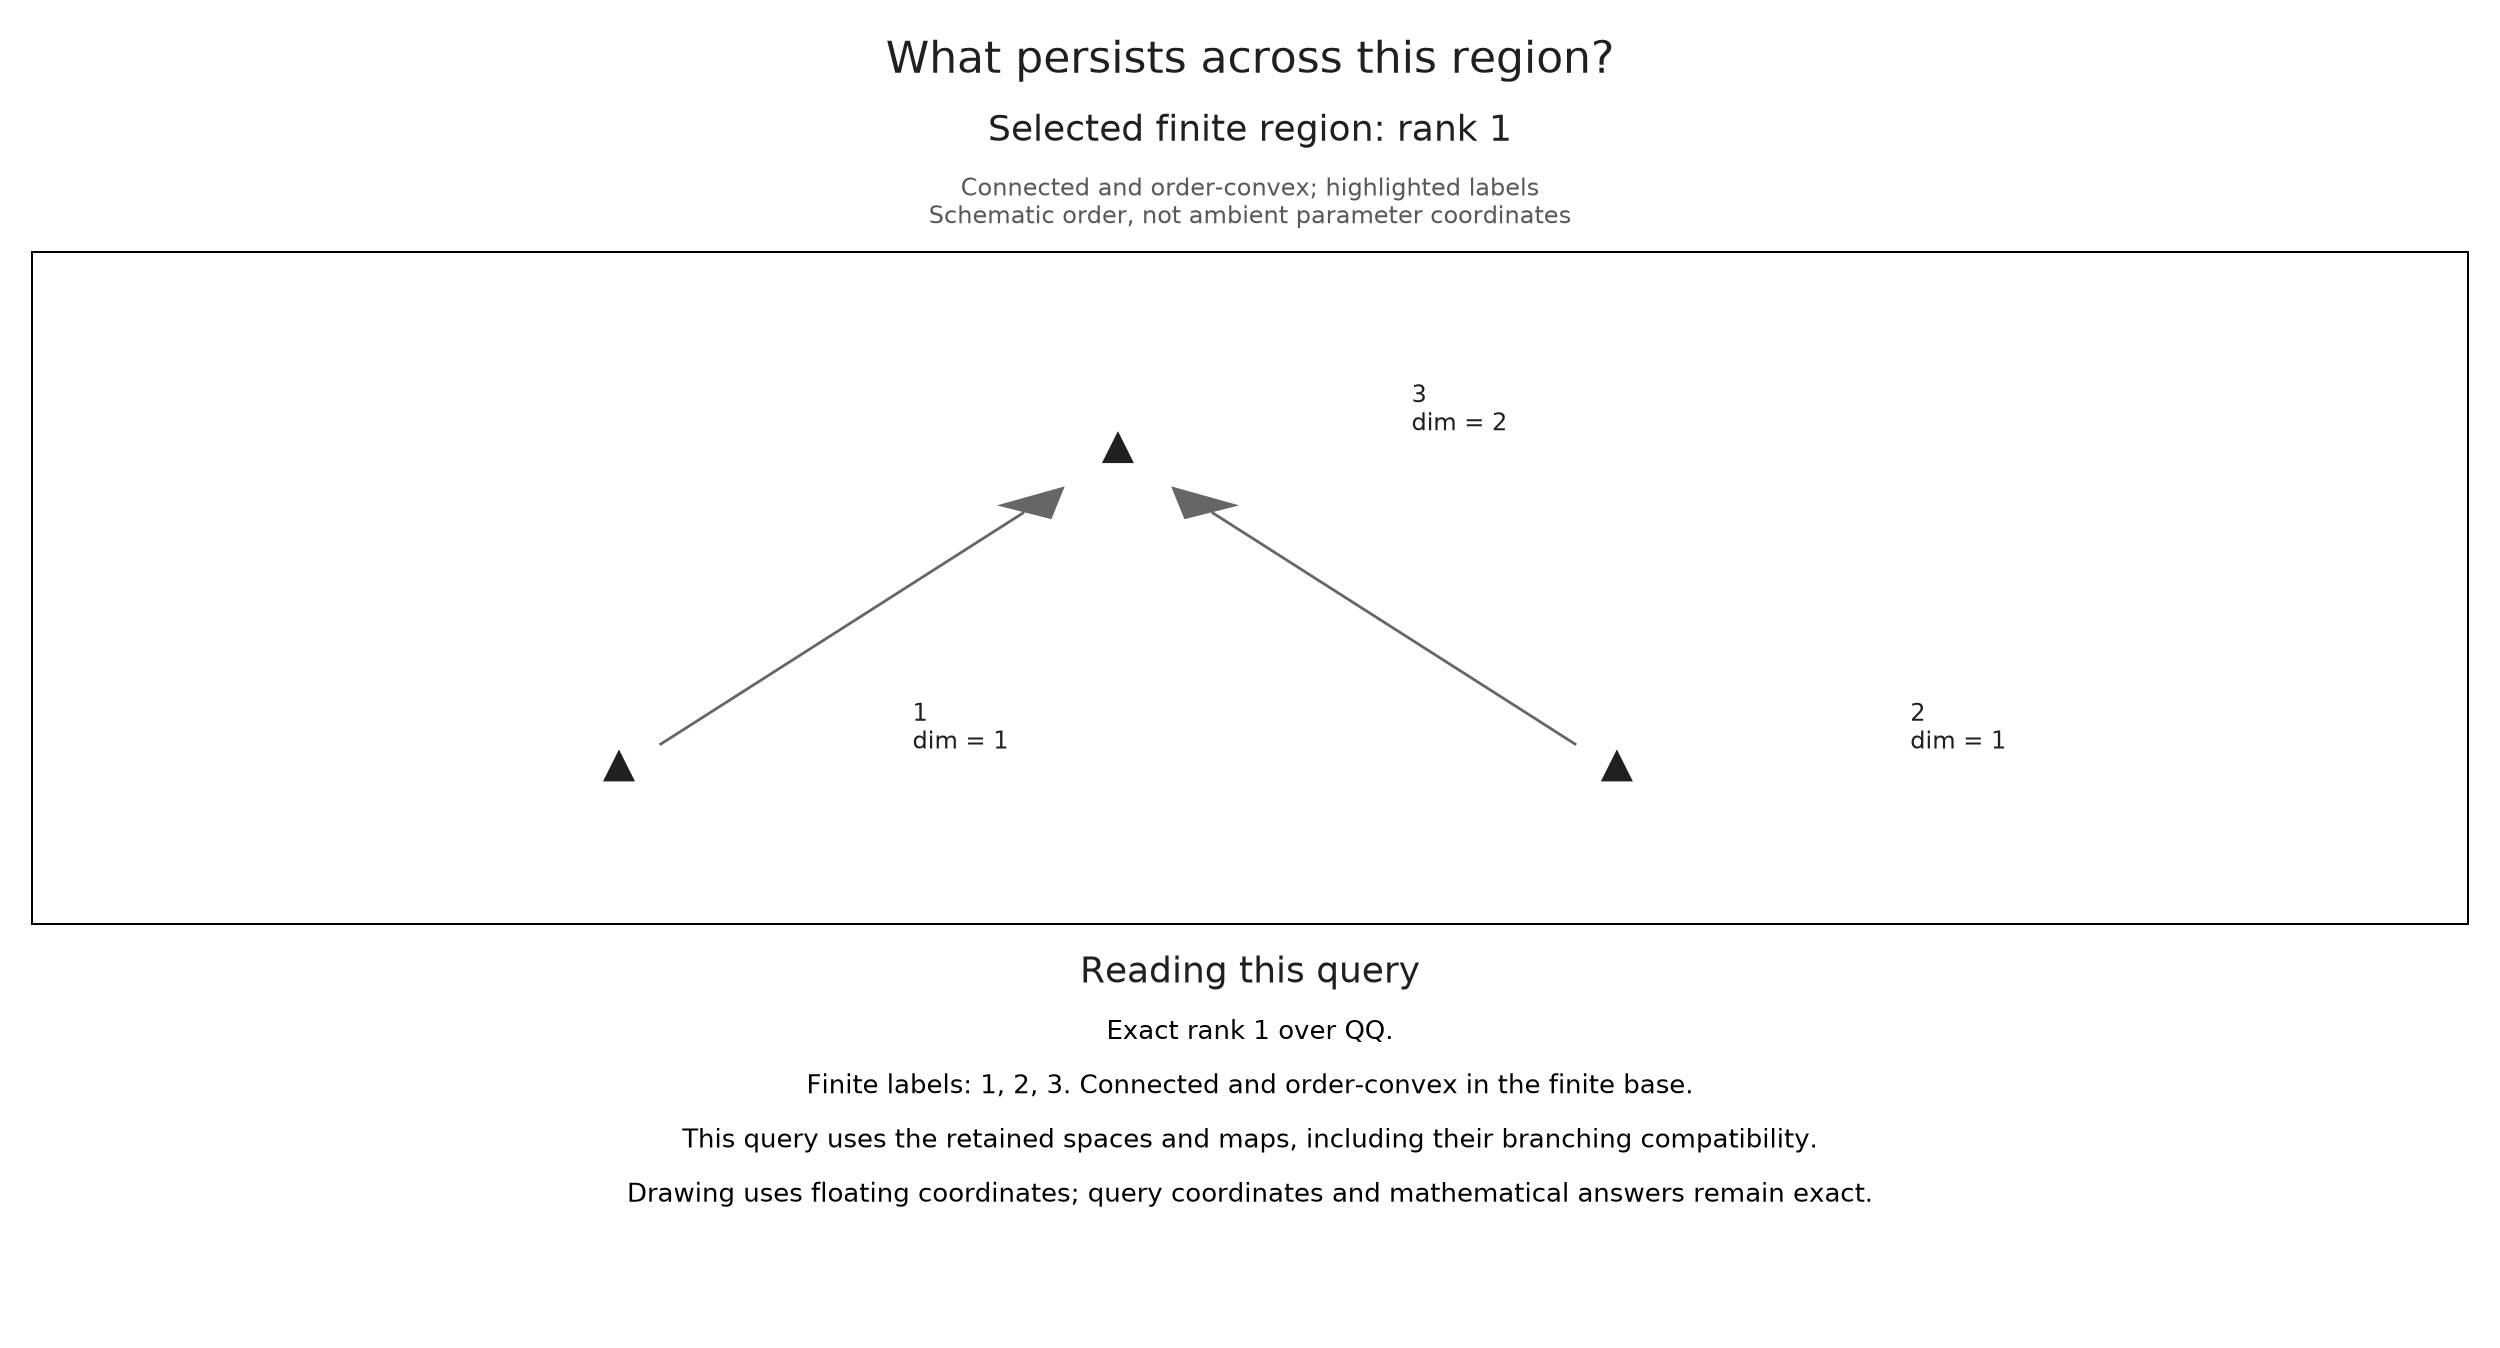

In [3]:
OP.visualize(parallel; kind=:generalized_rank, vertices=1:3)

The highlighted vertices form the query. Their drawing is a schematic order diagram: horizontal distance is not a parameter distance. Replacing `parallel` by `transverse` changes the rank to zero although the dimensions and individual arrow ranks agree.

A finite-label region must be nonempty, connected by comparability, and order-convex: if it contains both ends of an order interval, it must contain the labels between them. `[1, 2]` is disconnected in this fork. We can check that without running elimination.

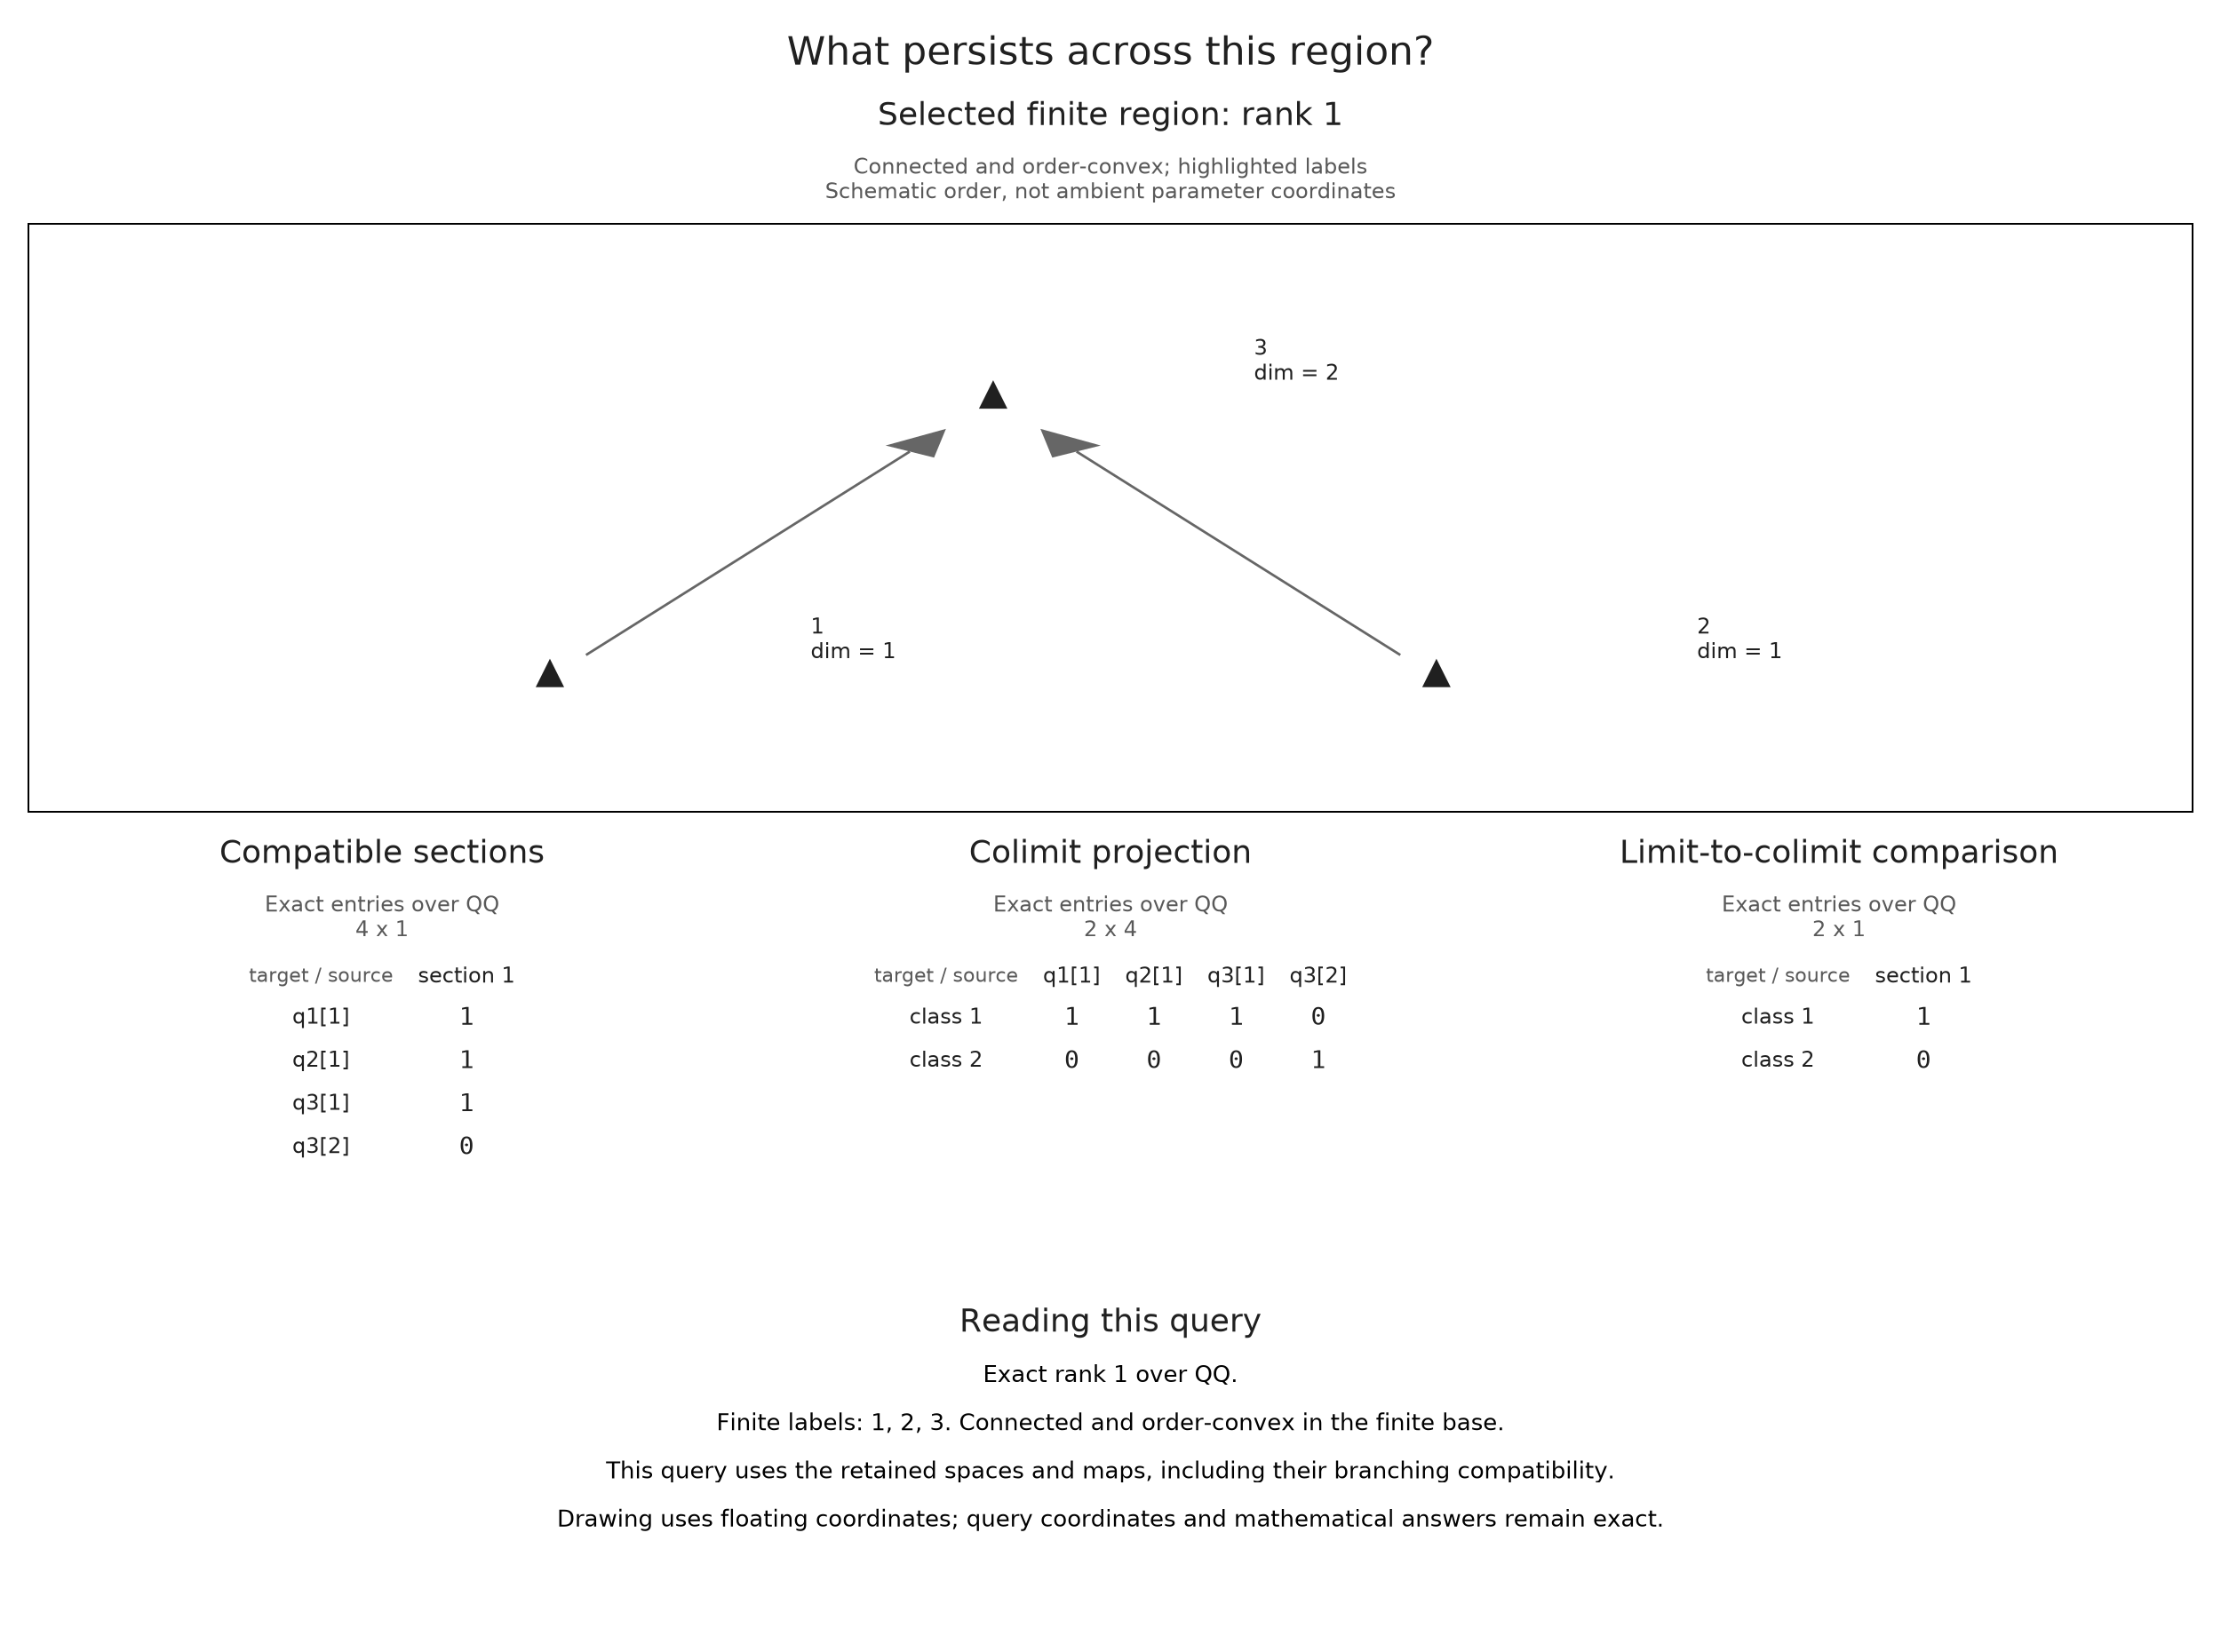

In [4]:
@assert !A.check_generalized_rank_region(parallel; vertices=[1, 2]).valid
session = OP.generalized_rank_session(parallel; vertices=1:3)
A.select_inspection!(session; witnesses=true)
@assert A.inspection_summary(session).rank == 1
OP.visualize(A.inspection_snapshot(session))

The matrices are an explicit opt-in. Rows and columns refer to the displayed stalk coordinates; the basis choices are not canonical. For this fork, the comparison matrix has one independent column. The scalar query remains the usual starting point.

**Try a variation.** Select only the arrow from vertex 2 to vertex 3 in the transverse module. Its rank is still one. This explains why losing the common class across both branches does not make either individual map zero.

In [5]:
@assert OP.generalized_rank(transverse; vertices=[2, 3]) == 1
A.close_inspection!(session);

GeneralizedRankInspectionSession(mode=finite, rank=1, closed=true)

## Use a declared family for signed reconstruction

Three lines entering a plane provide a useful second question. Query the target and each of the three branches separately. Each branch has rank one, while the target has dimension two. Signed coefficients correct the overlap when we reconstruct those four queries. A negative coefficient is a correction, not a negative-dimensional summand.

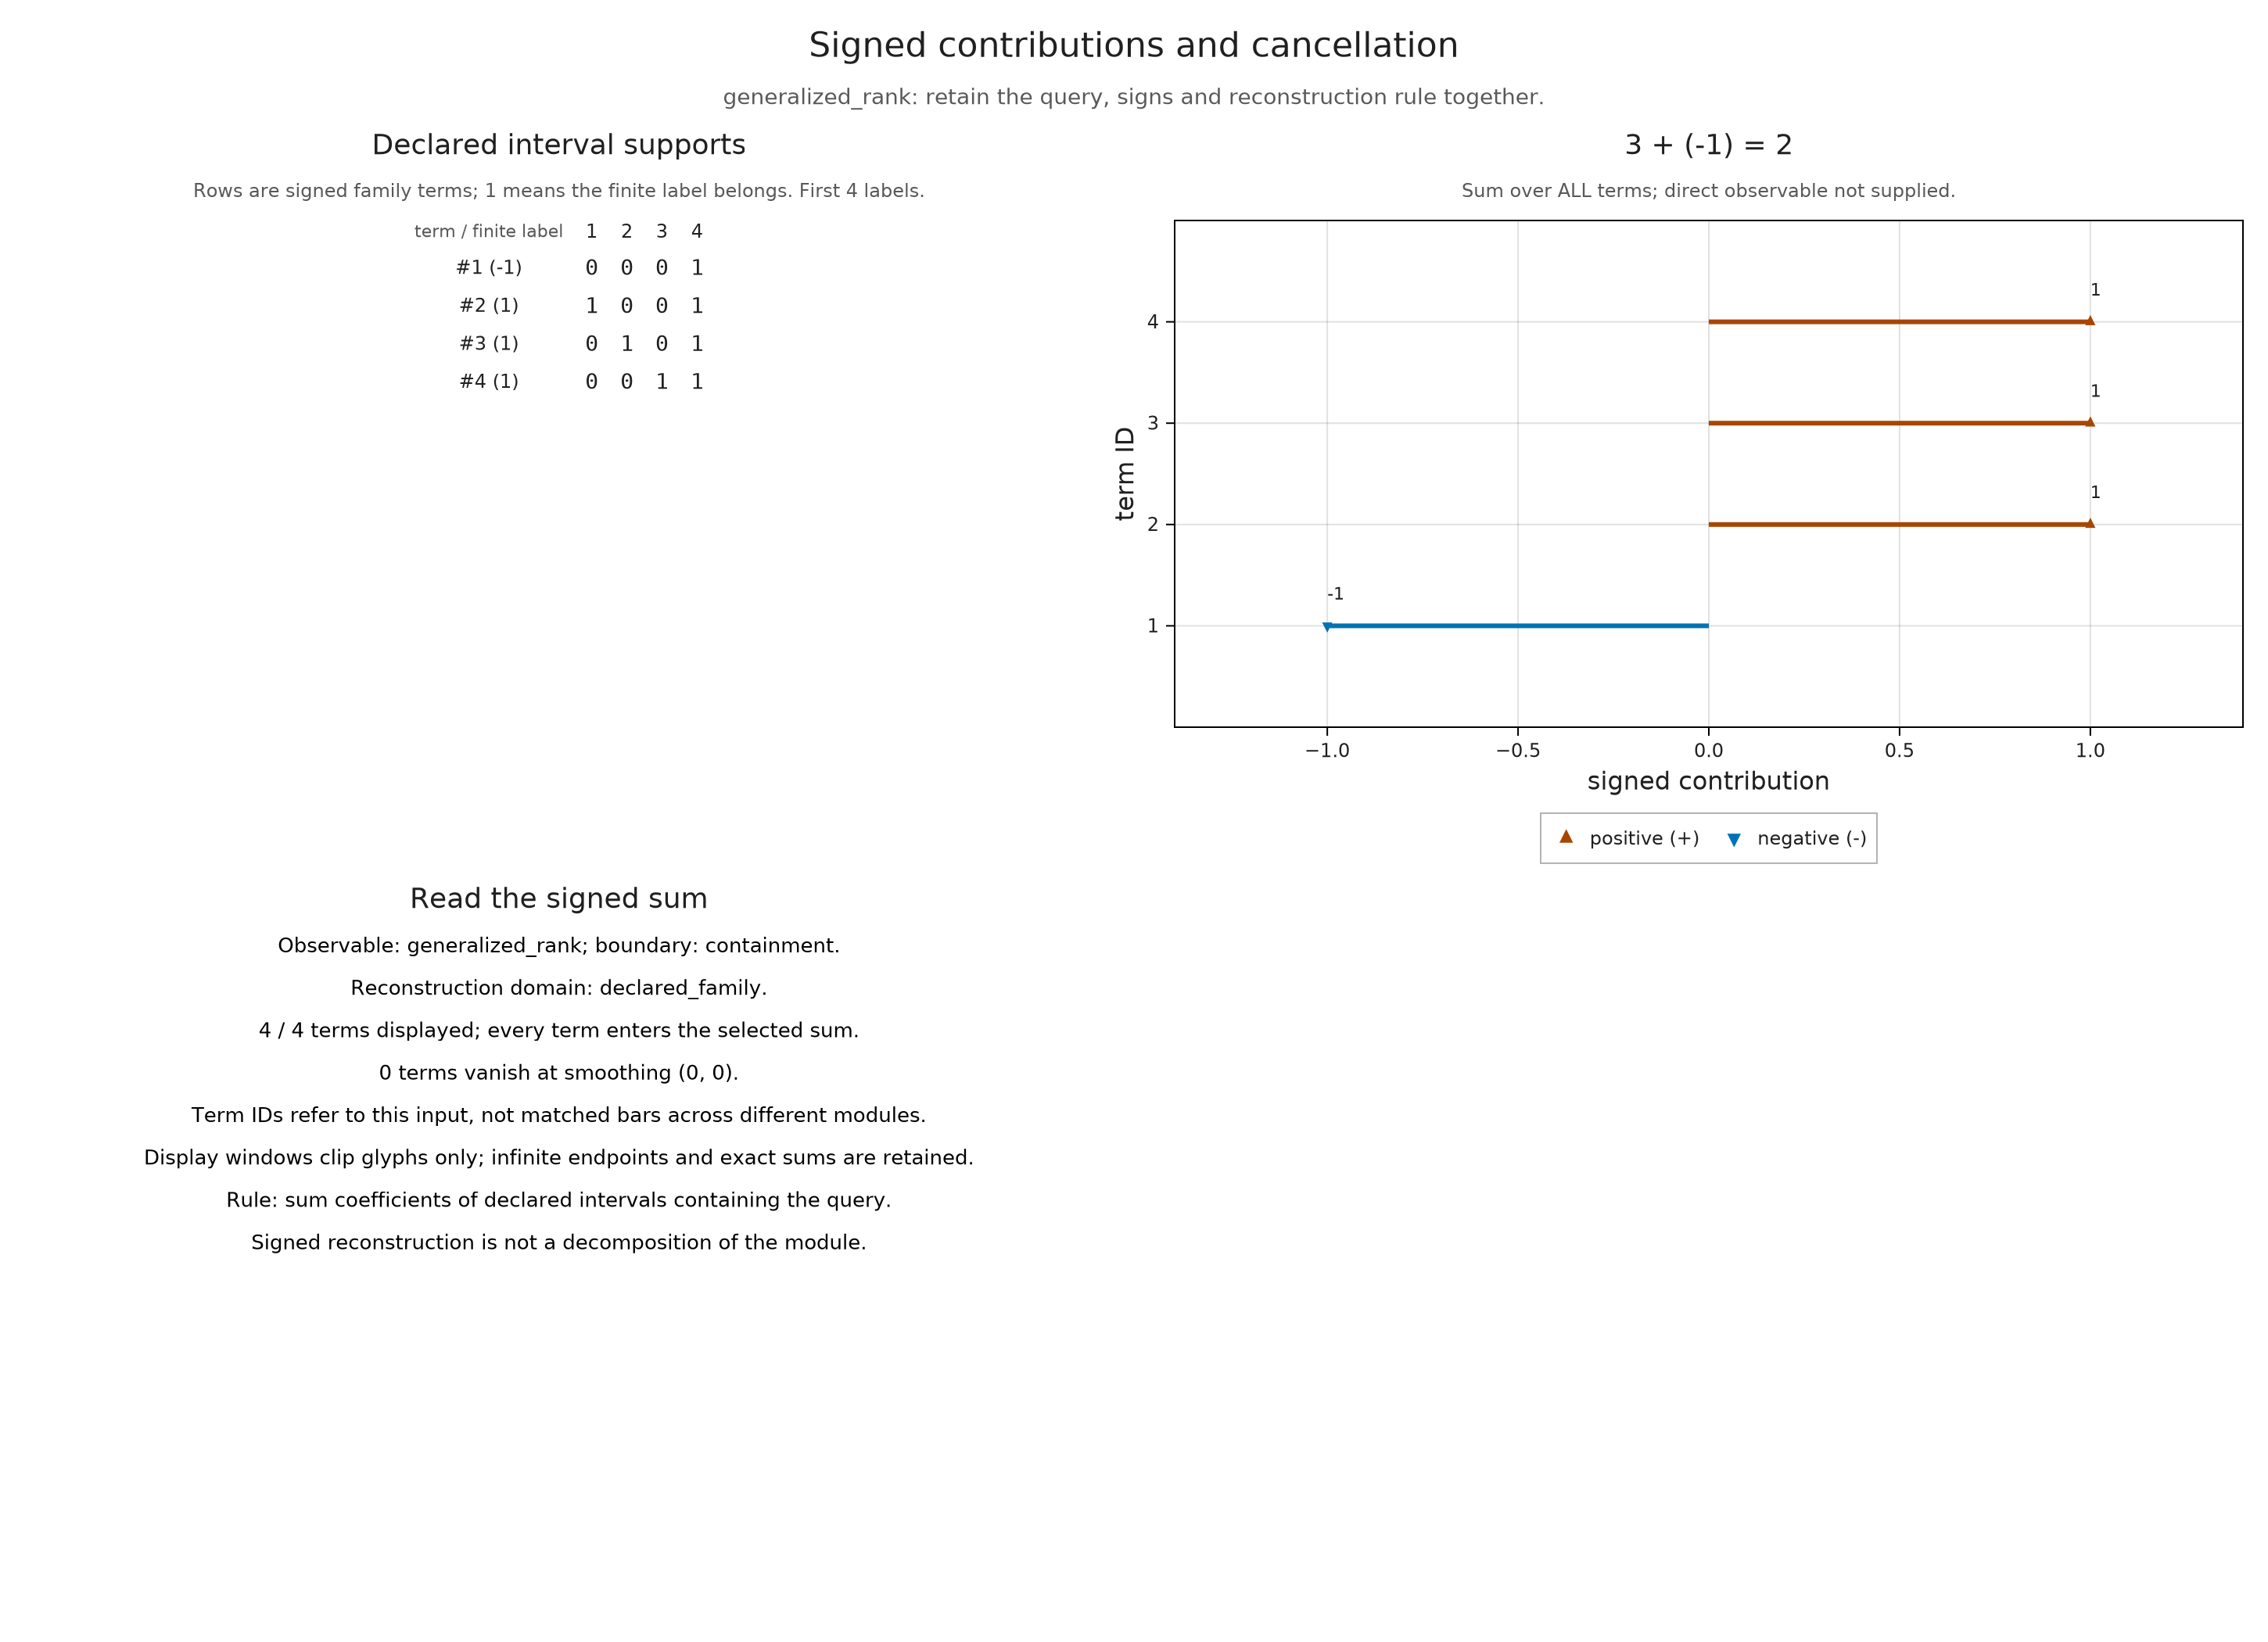

In [6]:
star = A.FinitePoset(Bool[1 0 0 1; 0 1 0 1; 0 0 1 1; 0 0 0 1])
three_lines = A.PModule{QQ}(star, [1, 1, 1, 2],
    Dict((1, 4) => reshape(QQ[1, 0], 2, 1),
         (2, 4) => reshape(QQ[0, 1], 2, 1),
         (3, 4) => reshape(QQ[1, 1], 2, 1)); field)
signed = OP.interval_rank_summary(three_lines; family=[[4], [1, 4], [2, 4], [3, 4]])
@assert A.interval_coefficients(signed) == [-1, 1, 1, 1]
@assert A.reconstruct_rank(signed; vertices=[4]) == 2
OP.visualize(signed; query=(vertices=[4],))

Reconstruction is certified only on the supplied family. An undeclared region is a new rank query, not something this incomplete signed table necessarily determines. The [signed-view guide](slices_diagrams.ipynb) explores contribution selection in more detail.

## Read a grid region through its boundary zigzag

Now retain an explicit grid encoding. Its nine labels have product order, with the first coordinate varying fastest. We give three interval summands directly: one on the whole grid, one on the lower-right square, and one on the upper-left square. Each stalk has a coordinate for each active summand, and the maps preserve the coordinates that continue.

The region `2:8` omits the two opposite corners. Only the whole-grid summand covers it. Its generalized rank should therefore be one. The axes have unequal spacings so that lattice indices and original parameter coordinates remain visibly different concepts.

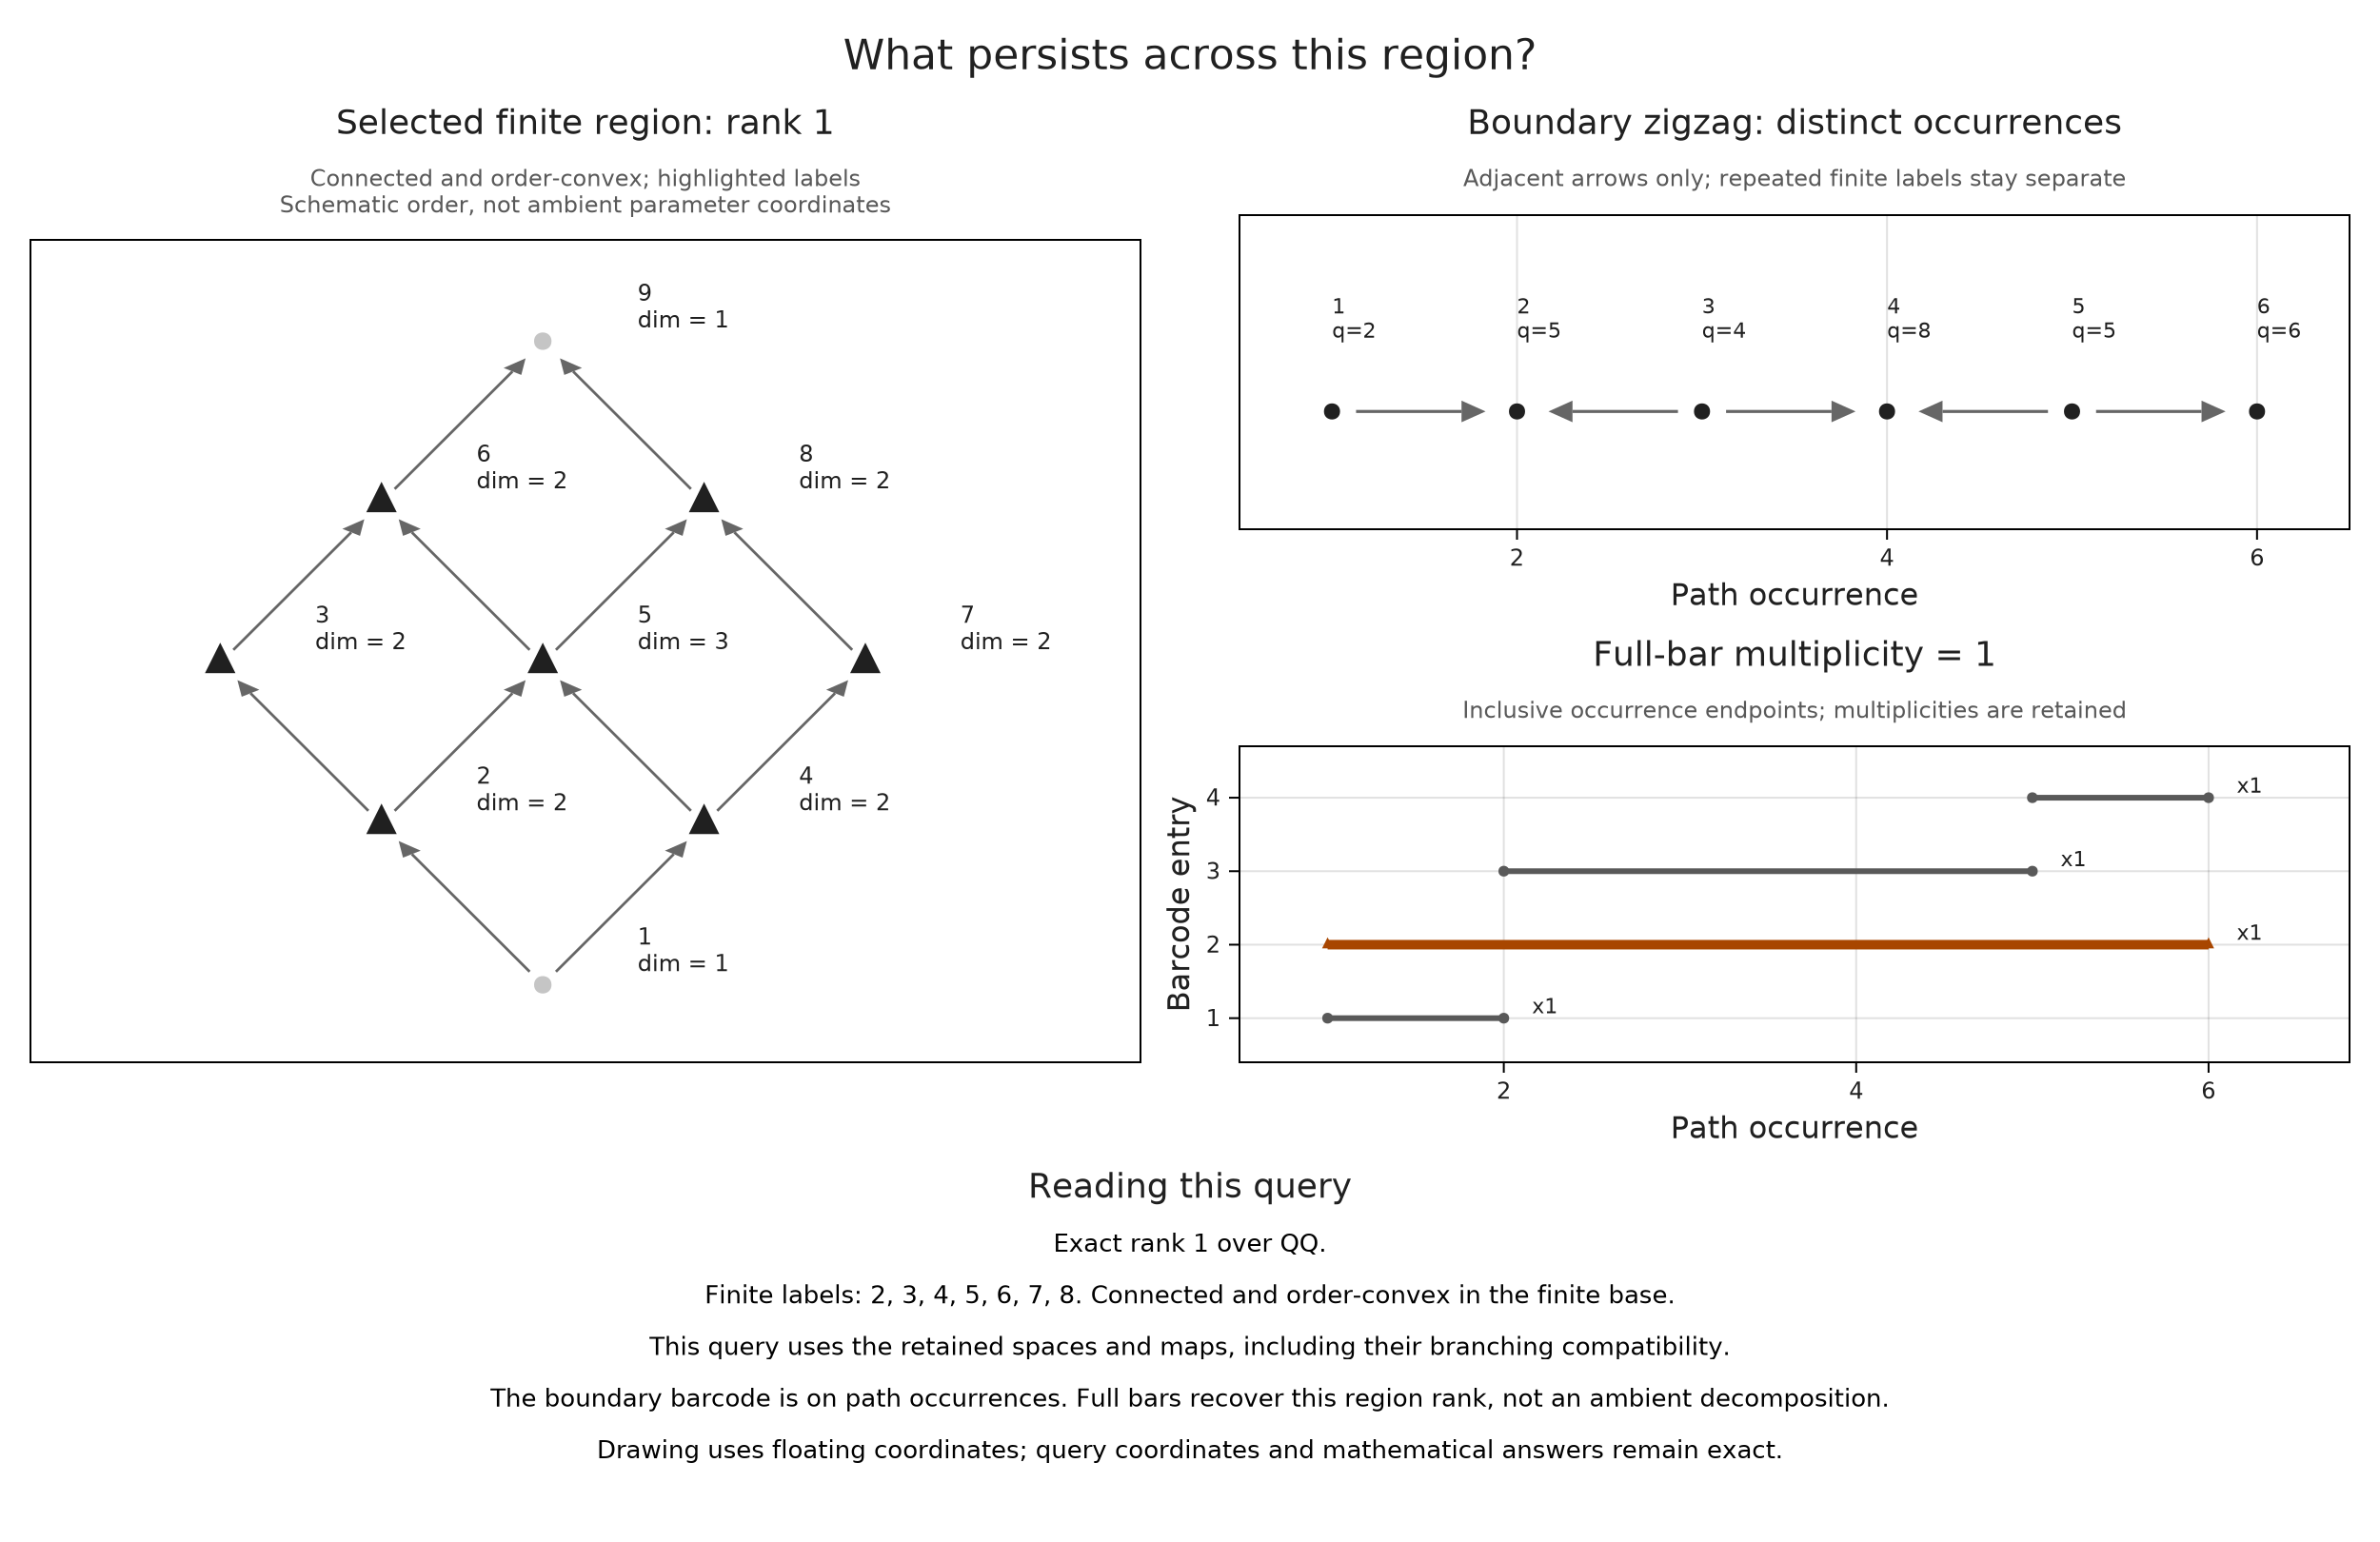

In [7]:
grid_poset = A.ProductOfChainsPoset((3, 3))
supports = [collect(1:9), [2, 3, 5, 6], [4, 5, 7, 8]]
active = [findall(s -> q in s, supports) for q in 1:9]
grid_maps = Dict((a, b) => QQ[i == j for i in active[b], j in active[a]]
                for (a, b) in A.cover_edges(grid_poset))
grid_module = A.PModule{QQ}(grid_poset, length.(active), grid_maps; field)
grid = A.GridEncodingMap(grid_poset, ([0, 2, 4], [0, 3, 6]))
encoded = OP.EncodingResult(grid_poset, grid_module, grid)
boundary_session = OP.generalized_rank_session(encoded; vertices=2:8, boundary=true)
@assert A.inspection_summary(boundary_session).rank == 1
OP.visualize(A.inspection_snapshot(boundary_session))

The boundary path visits labels `2, 5, 4, 8, 5, 6`. The two visits to label 5 are different positions. Arrows relate adjacent occurrences; they do not add every comparison between the underlying grid labels. The barcode uses these occurrence indices and includes both endpoints. Its full bar covers every occurrence, and its multiplicity is the region rank.

This is the boundary-cap theorem for connected convex intervals in a two-dimensional **index lattice**. It does not turn an arbitrary path into a generalized-rank witness, and it does not claim that the ambient module decomposes into the displayed bars. The [algorithm account](../implementation/generalized_rank.md#an-optional-boundary-zigzag-witness) explains the construction and its bounded cost.

In [8]:
boundary = A.boundary_zigzag(grid_module, grid; vertices=2:8)
@assert A.boundary_path(boundary).vertices == [2, 5, 4, 8, 5, 6]
@assert OP.generalized_rank(boundary) == 1
A.select_inspection!(boundary_session; occurrence=5)
OP.describe(boundary)

(kind = :boundary_zigzag, rank = 1, occurrences = 6, distinct_labels = 5, intervals = 4, queries = 22, interpretation = :finite_grid_interval, field = TamerOp.CoreModules.CoeffFields.QQField())

## Move from finite labels to a continuous worm

For a geometric region, the encoding assignment matters. Consider a single line that exists throughout the quadrant $[0,\infty)^2$. One finite label suffices to encode it. We explicitly use the grid convention: half-open cells, zero below either first axis coordinate, and a constant extension above the final coordinates.

A worm centered at $p=(p_x,p_y)$ with width $d$ and length $\ell$ satisfies

$$|x-p_x|\leq\ell d,\quad |y-p_y|\leq\ell d,\quad |x+y-p_x-p_y|\leq2d.$$

Length one gives a square. Larger lengths stretch it along the anti-diagonal and retain the diagonal sides. The region is closed; it is not replaced by a few sampled squares.

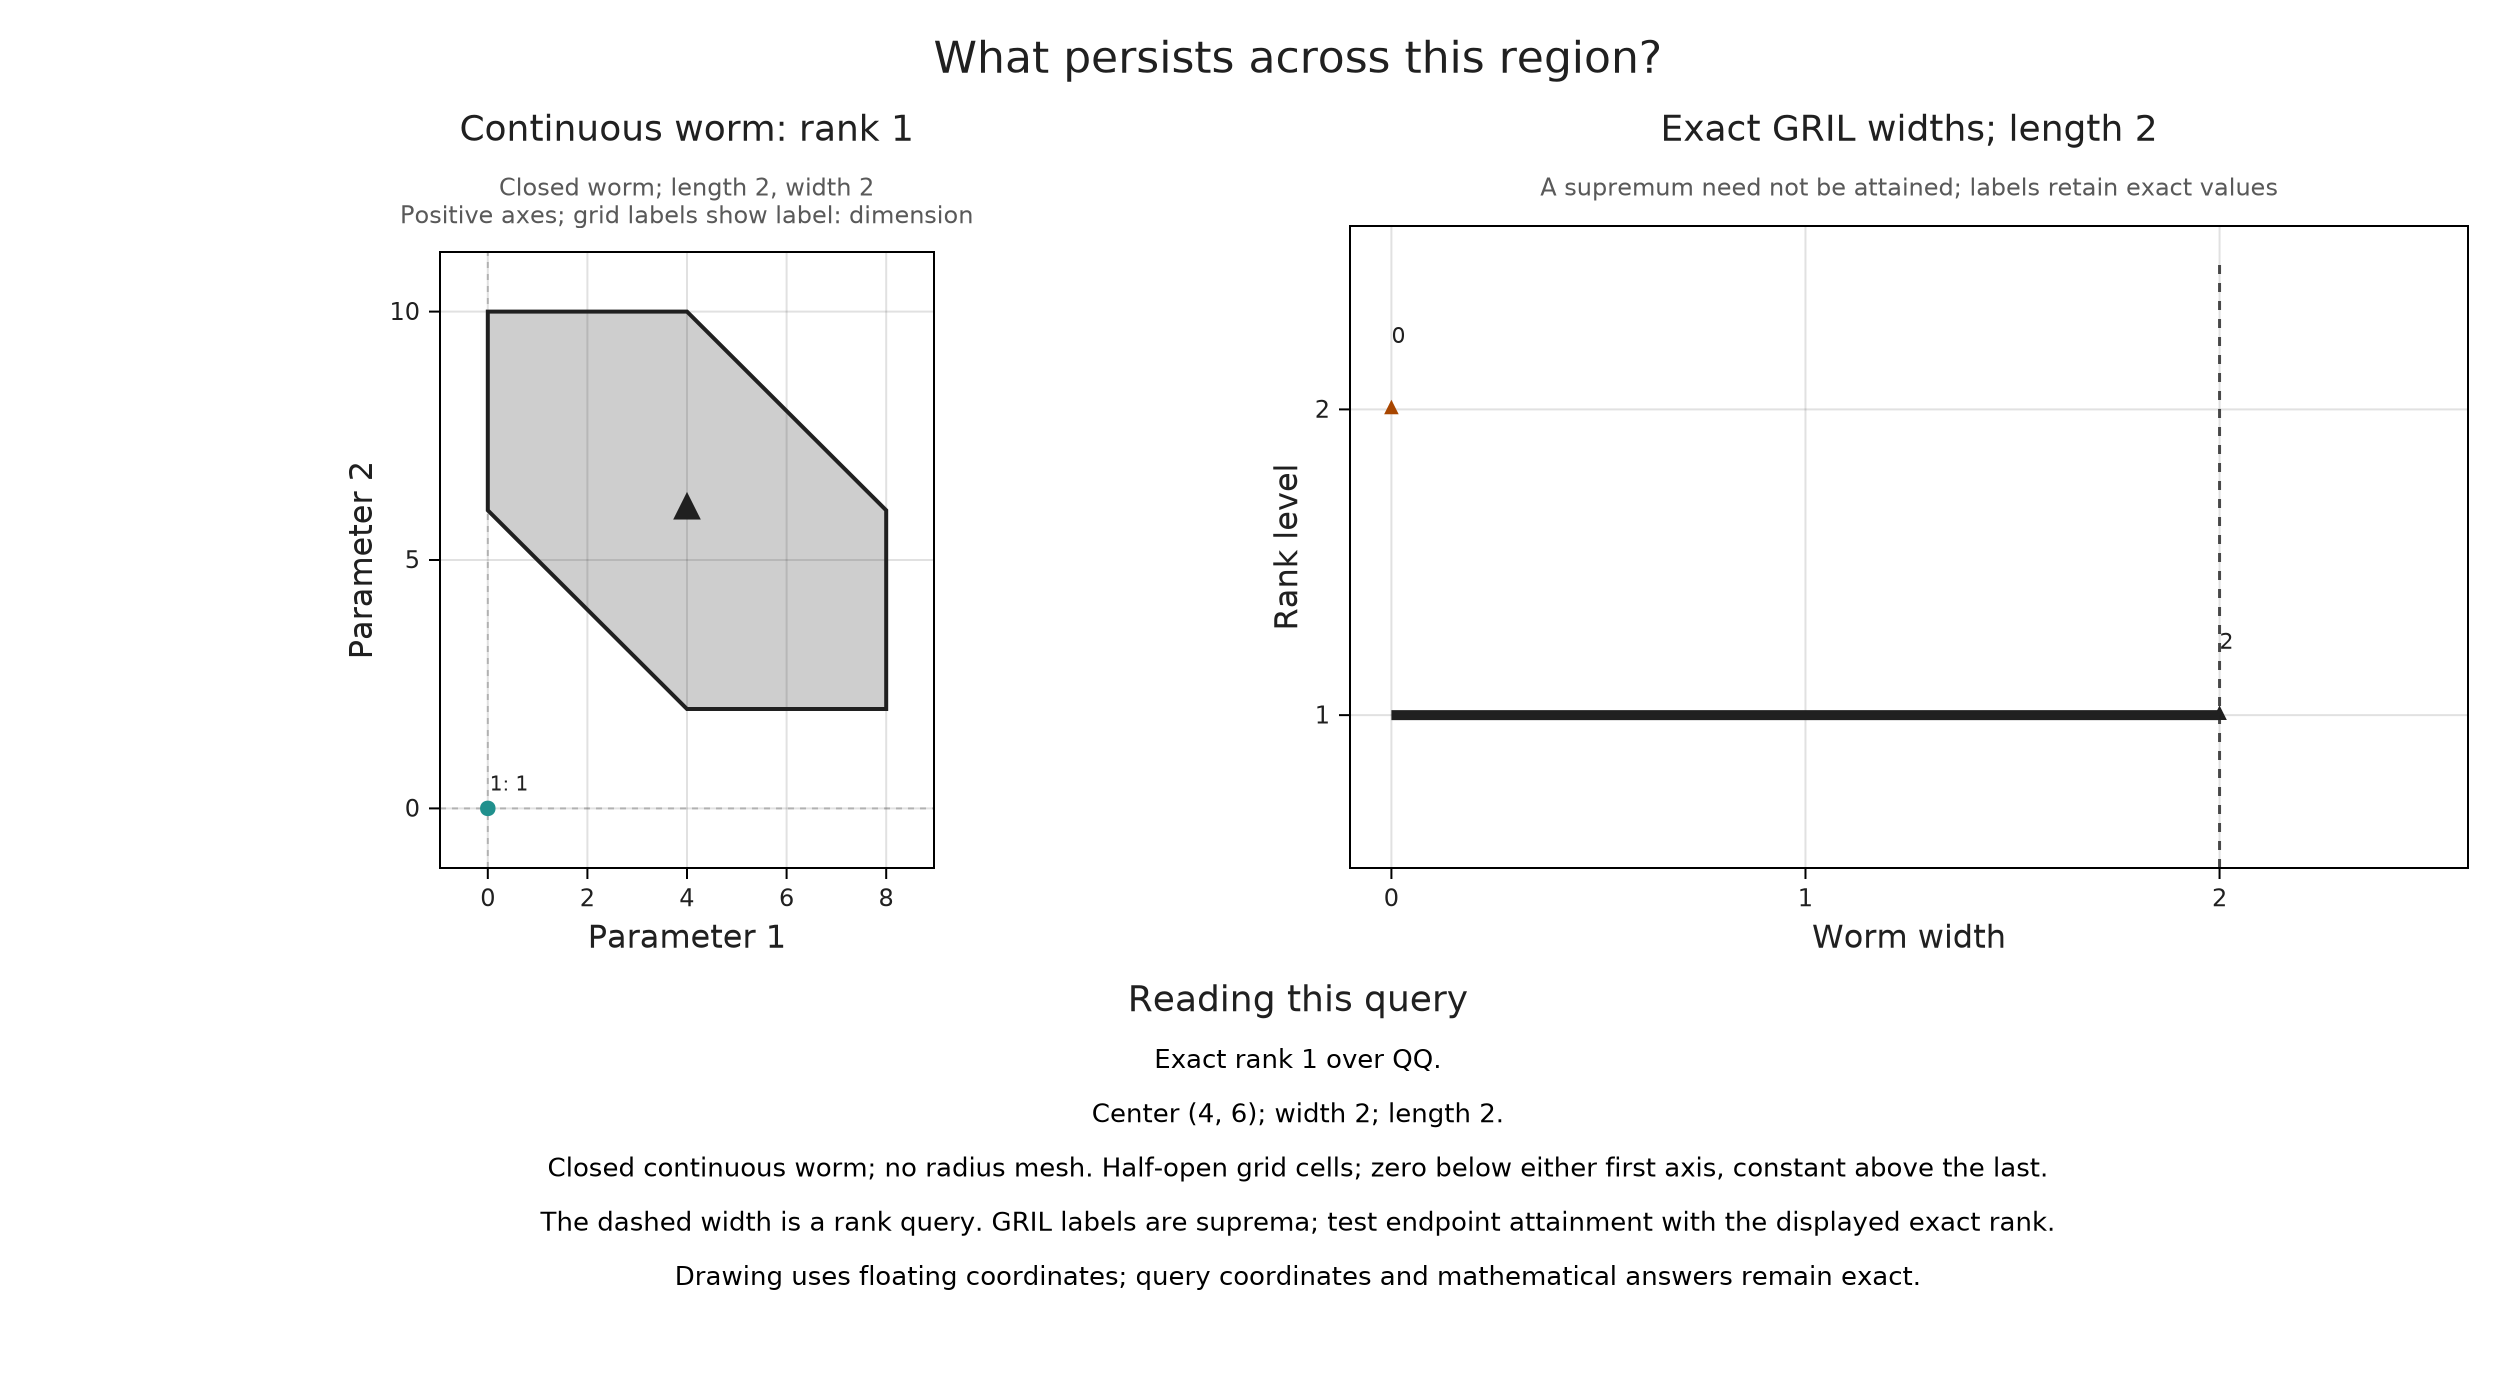

In [9]:
one_label = A.ProductOfChainsPoset((1, 1))
quadrant_module = A.PModule{QQ}(one_label, [1],
    Dict{Tuple{Int,Int},Matrix{QQ}}(); field)
quadrant_grid = A.GridEncodingMap(one_label, ([0], [0]))
quadrant = OP.EncodingResult(one_label, quadrant_module, quadrant_grid)
worm_session = OP.generalized_rank_session(quadrant; center=(4, 6), width=2, length=2,
    levels=(1, 2), lengths=(1, 2, 4))
@assert A.inspection_summary(worm_session).rank == 1
OP.visualize(A.inspection_snapshot(worm_session))

GRIL asks for the supremum of the widths whose rank is at least a chosen level $k$. In this quadrant, the first contact with the zero-below extension occurs after width $4/\ell$. Thus the level-one widths for lengths 1, 2 and 4 are exactly 4, 2 and 1. Level two is zero because the module never has two independent classes.

The dashed line marks the currently queried width. Its rank answers an endpoint question that the GRIL supremum alone cannot settle. Here the endpoint itself is included: width 2 still has rank one at length 2. Increasing it slightly gives zero.

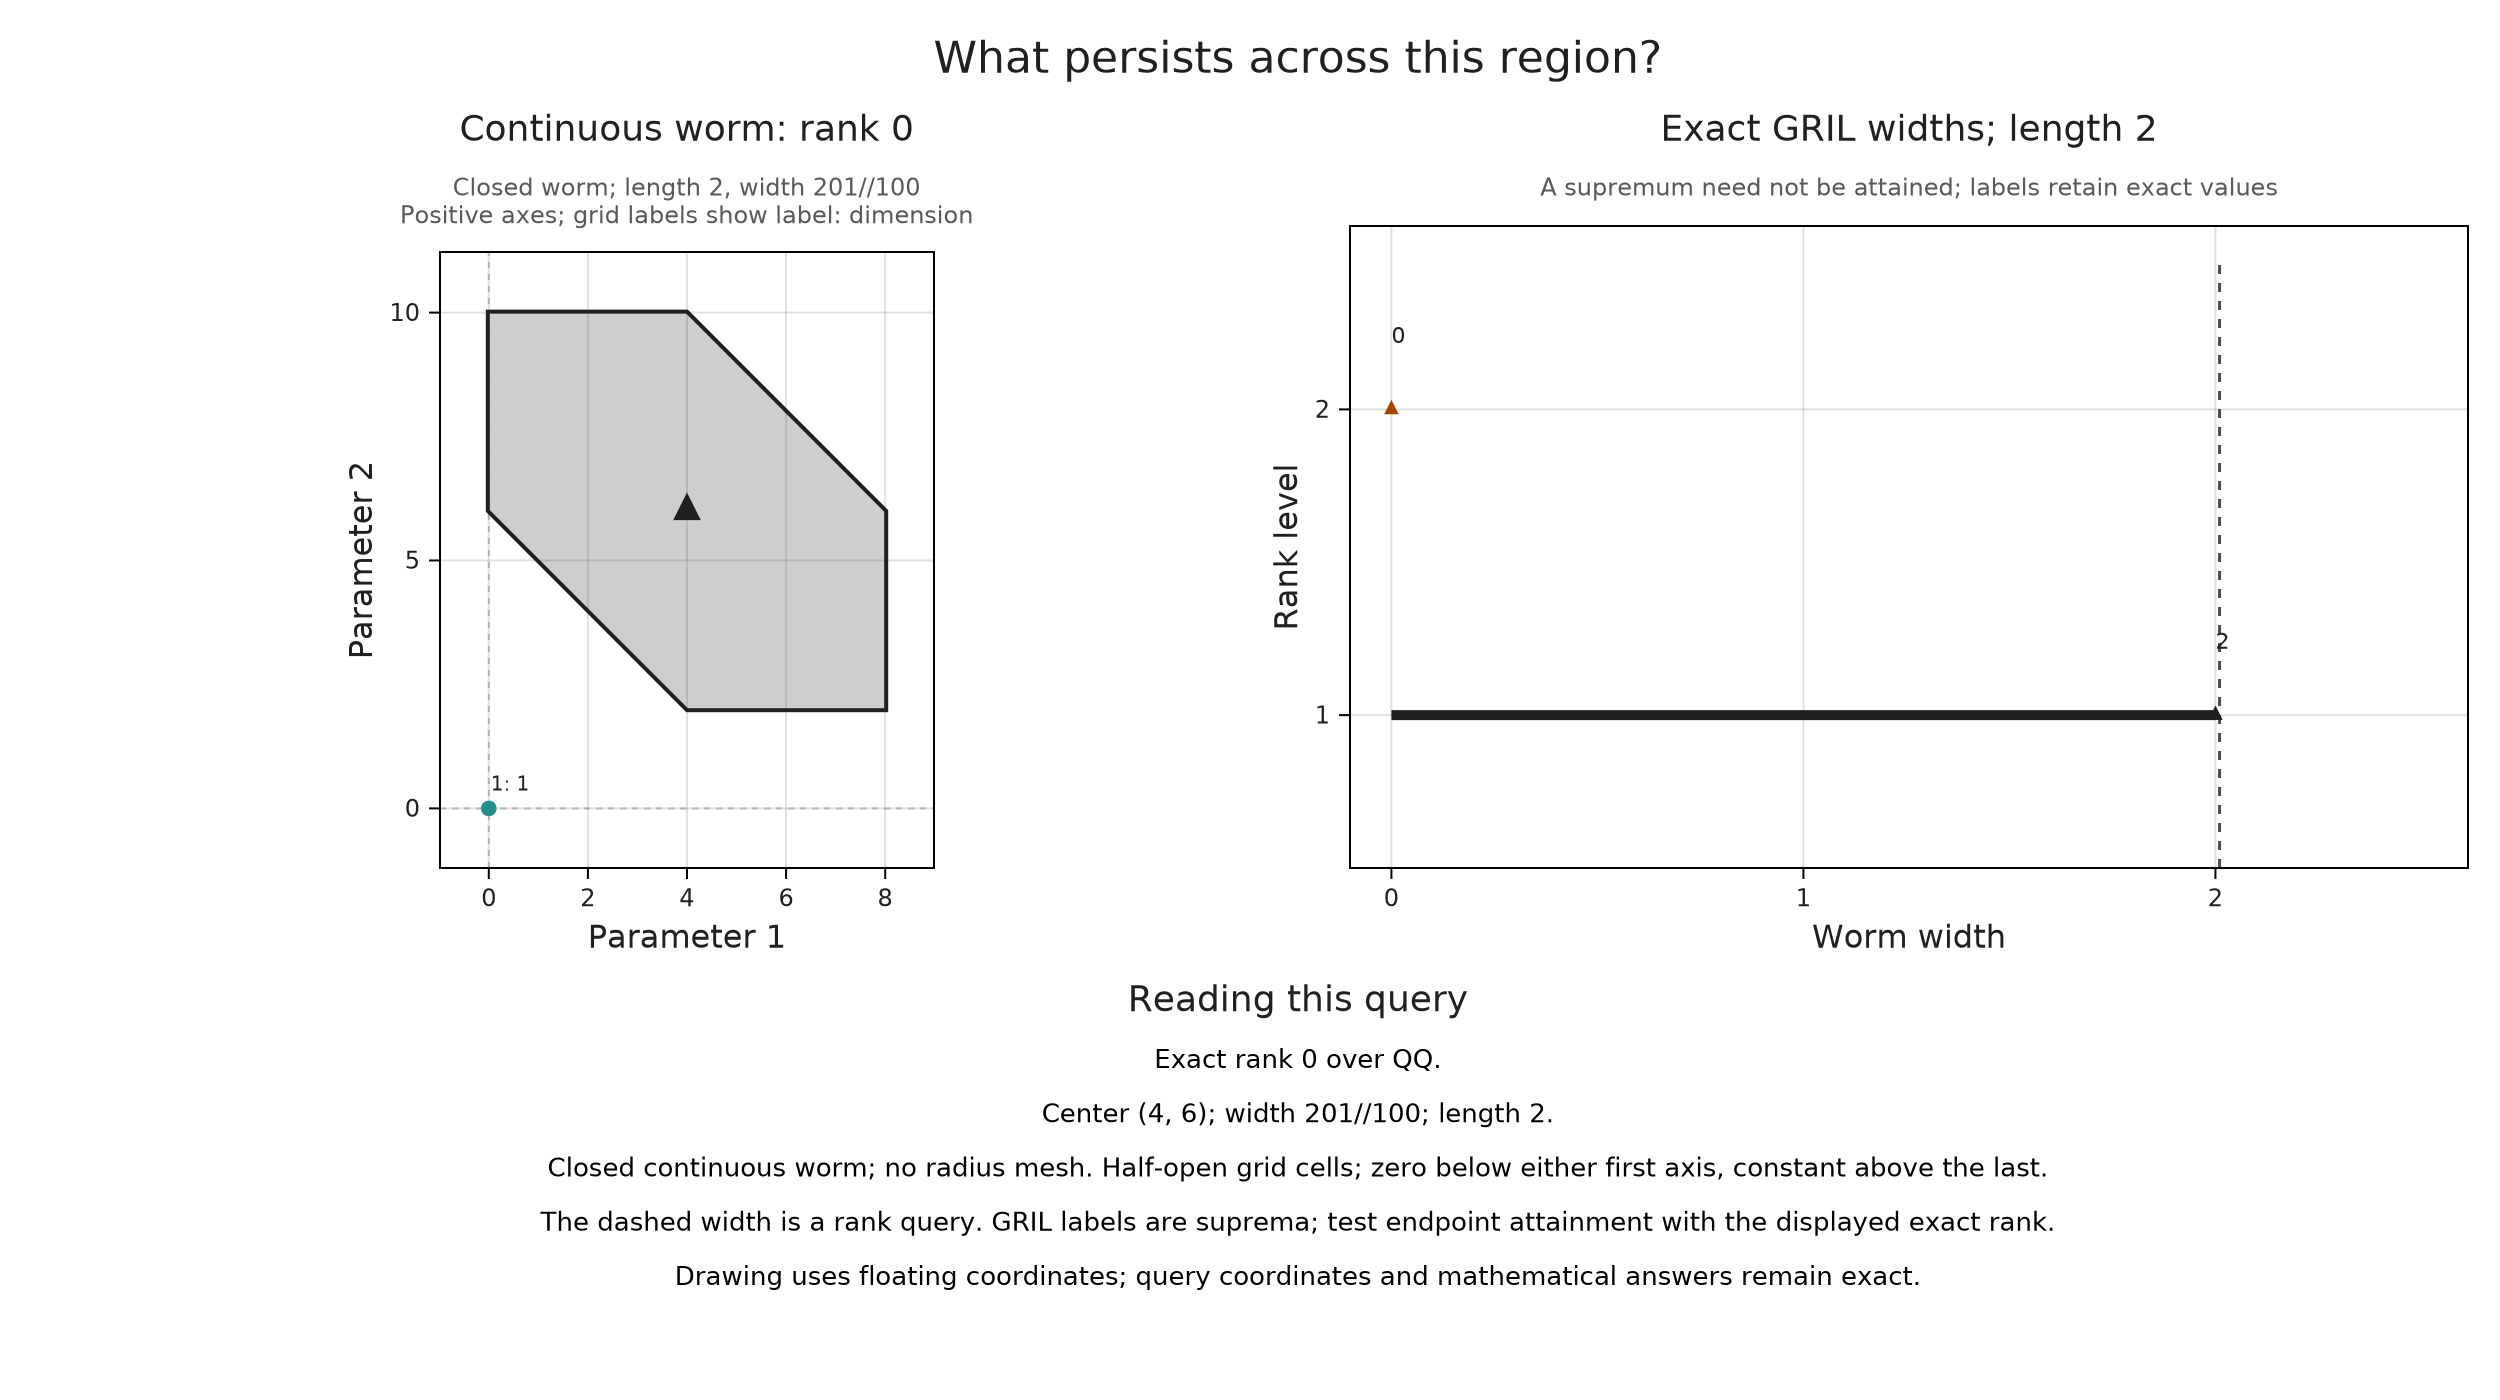

In [10]:
landscape = OP.gril(quadrant; centers=[(4, 6)], levels=(1, 2), lengths=(1, 2, 4))
@assert A.gril_values(landscape) == reshape(QQ[4, 0, 2, 0, 1, 0], 1, 2, 3)
A.select_inspection!(worm_session; width=201//100)
@assert A.inspection_summary(worm_session).rank == 0
OP.visualize(A.inspection_snapshot(worm_session))

Changing width reuses the landscape. Selecting a retained rank level only redraws it. Moving the center computes a new bounded probe family. Returned arrays are ordered `(center, level, length)`; `A.feature_vector` flattens with the center varying fastest. Exact widths at fixed centers do not supply values between those centers.

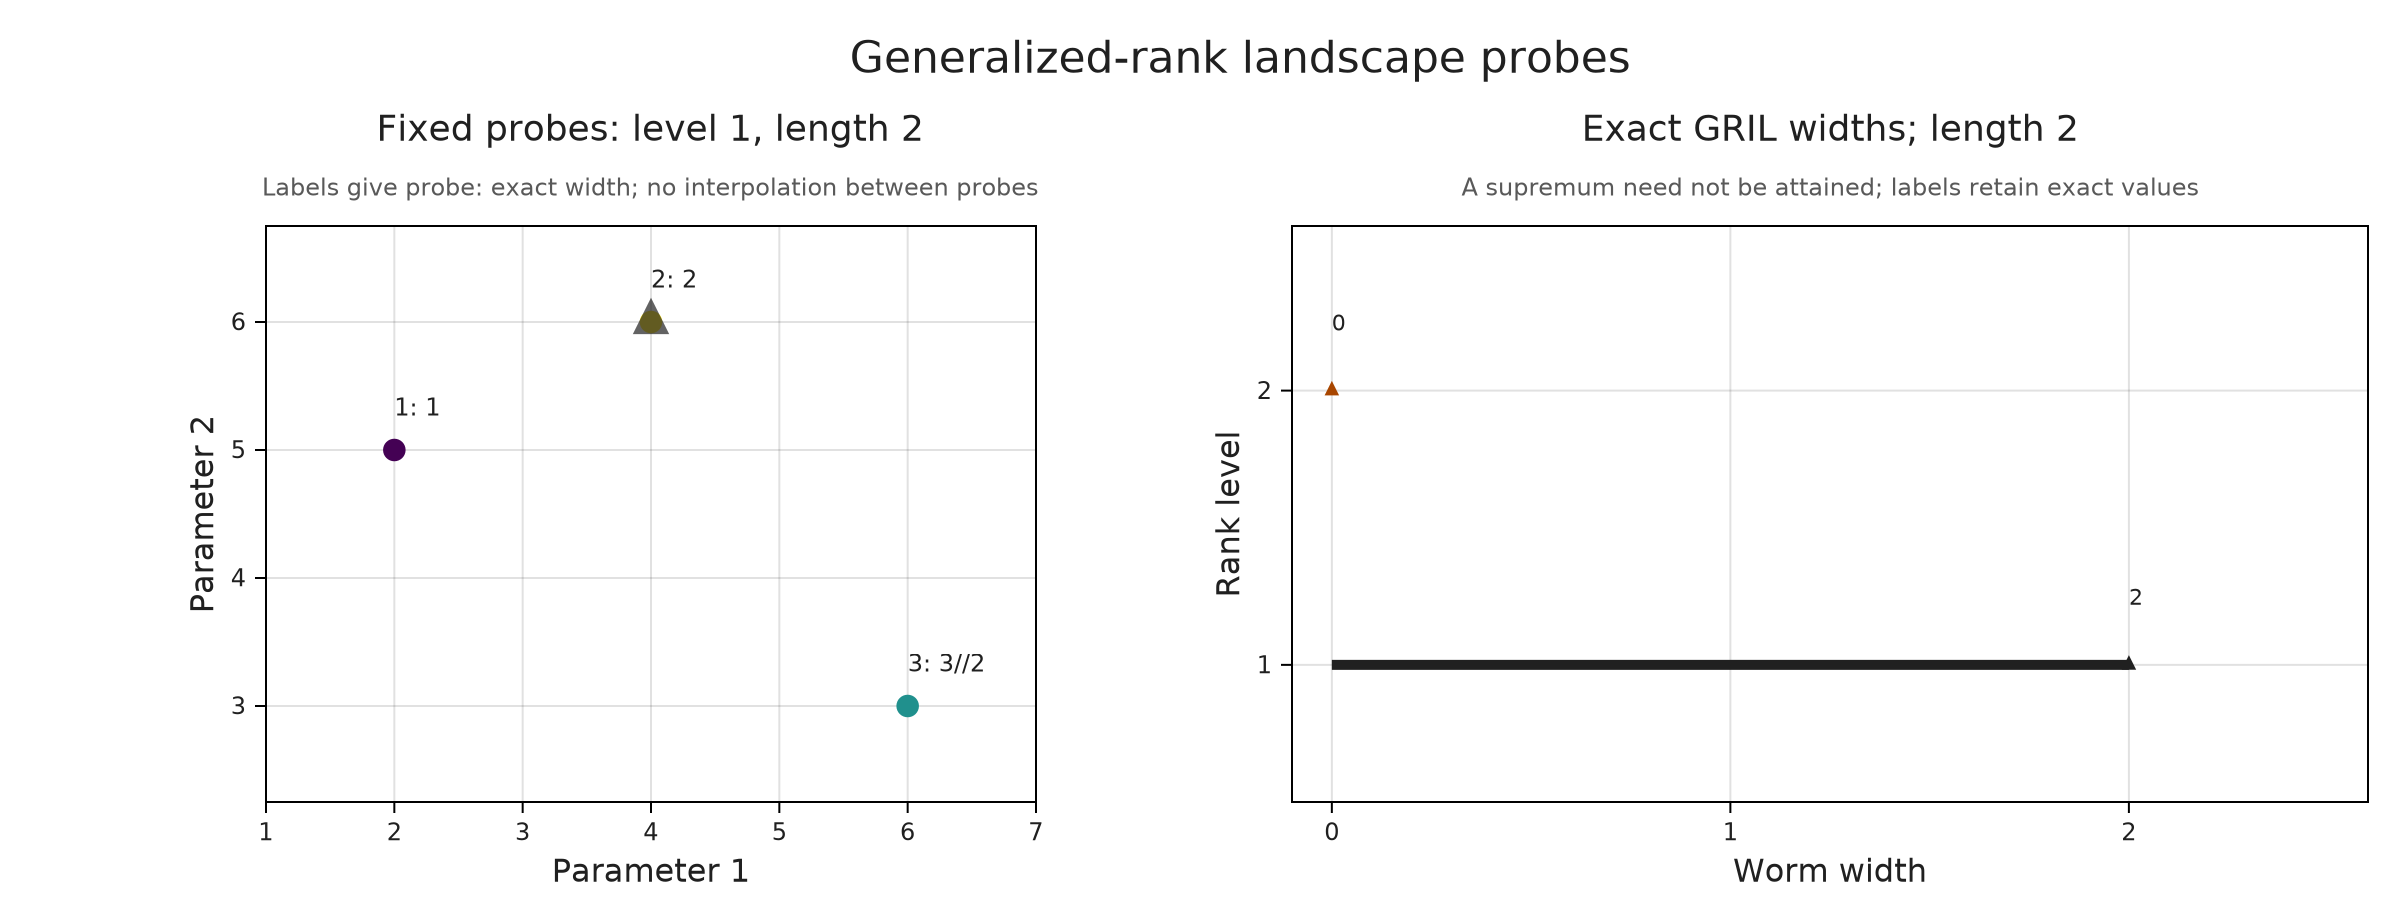

In [11]:
probes = OP.gril(quadrant; centers=[(2, 5), (4, 6), (6, 3)], levels=(1, 2), lengths=(1, 2))
@assert A.gril_values(probes)[:, 1, 2] == QQ[1, 2, 3//2]
OP.visualize(probes; center=2, level=1, length=2)

## Explore the same queries live

In a Julia session with WGLMakie installed, evaluate the following to open live controls. These are the same sessions used by the static figures:

```julia
using WGLMakie
OP.visualize(boundary_session; backend=:wglmakie)
OP.visualize(worm_session; backend=:wglmakie)
```

Type exact rational coordinates such as `1/3`, select finite labels or boundary occurrences, and vary the worm width, length and rank level. Pointer coordinates are approximate. Hover reads the retained answer; it does not launch elimination. Invalid or over-budget requests leave the last valid state visible. All live queries require Julia. Exporting the static snapshot preserves its picture, not its callbacks.

The finite and continuous queries deliberately keep separate hypotheses. The lattice boundary barcode does not certify a continuous worm, and a finite-label query does not describe an unspecified ambient region. Learned probes and differentiation require different mathematical contracts.

## Optional: save a static view

A snapshot can be shared without a running Julia process. `save_visual` chooses a static export through the loaded renderer. Cosmetic styling stays separate from the query.

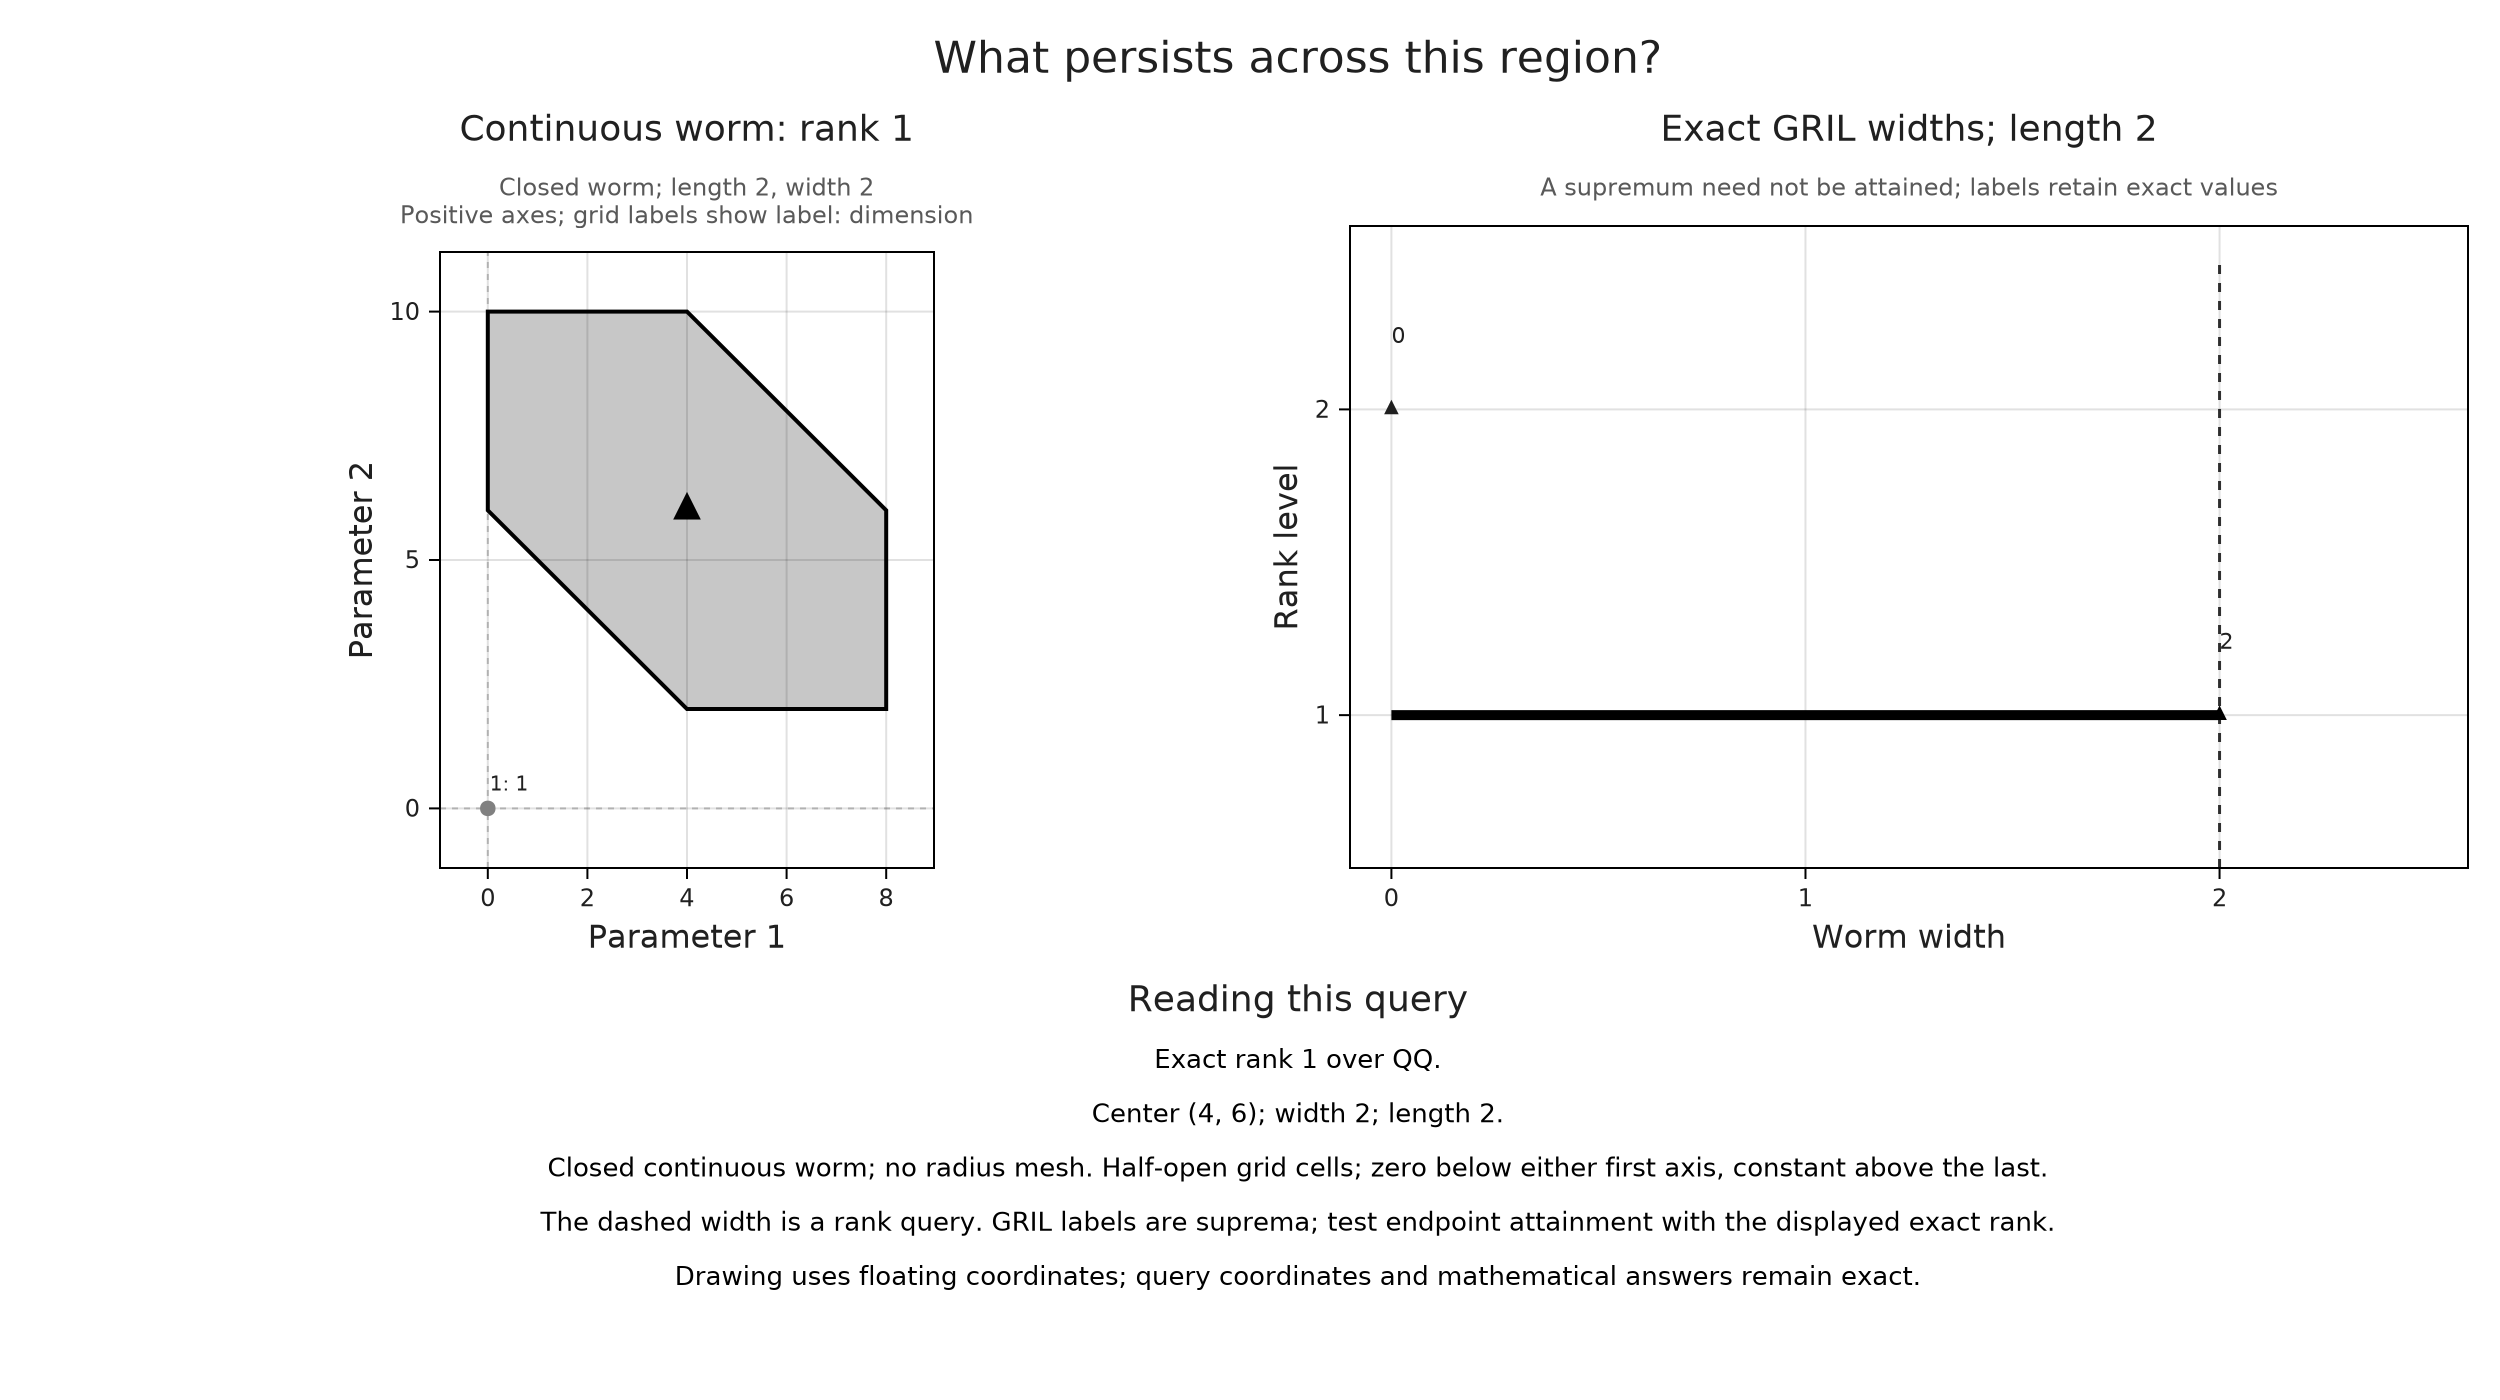

In [12]:
style = OP.VisualStyle(; palette=:grayscale)
A.select_inspection!(worm_session; width=2)
OP.visualize(A.inspection_snapshot(worm_session); style)

In [13]:
output_directory = mktempdir()
OP.save_visual(output_directory, "generalized-rank", A.inspection_snapshot(worm_session); style);

VisualExportResult
  stem: "generalized-rank"
  visual_kind: generalized_rank
  format: png
  backend: cairomakie
  path: "/tmp/jl_N8E6t2/generalized-rank.png"

Finite spaces and maps have now answered a branching rank query, a signed reconstruction, a boundary-barcode question and a geometric landscape query. For a focused starting example, use the [branching-region recipe](../recipes/query_region_invariant.md). To understand the stored constraints and exact width search, continue with [Computing generalized rank and GRIL](../implementation/generalized_rank.md).

In [14]:
A.close_inspection!(boundary_session)
A.close_inspection!(worm_session);

GeneralizedRankInspectionSession(mode=worm, rank=1, closed=true)